# Lab 5: Motor parameter identification
Name: **Yelbek Abdumajitov**

Student ID: **240066**

My M3 and M4 step tests use −100 to +100 PWM in steps of 5: 2 s on and 1 s off, after a 3 s zero-PWM check.

For the recent square-wave and low-PWM tests, the wheels were lifted. The display showed **12.3 V before and after**. I use this estimate for the main files, which have no logged voltage.


## Robot programs

The QRS files are visual programs made in TRIK Studio. They run on the robot, set the motor power and save encoder angle, time and PWM. The Python cells below analyse the saved TXT files; they do not run the QRS programs.

| QRS file | Purpose | Data file |
| --- | --- | --- |
| `motor_steps.qrs` | M4 step tests for speed and time-constant fitting | `steps_M4.txt` |
| `motor_steps_M3.qrs` | M3 step-test program adapted from M4 | `steps_M3.txt` |
| `motor_signal.qrs` | M4 square wave for the model comparison | `square_M4.txt` |
| `motor_square_M3.qrs` | M3 square wave for the model comparison | `square_M3.txt` |
| `motor_deadzone_M4.qrs` | M4 low-PWM test for the dead-zone check | `deadzone_M4_combined_runs.txt` |
| `motor_deadzone_M3.qrs` | M3 low-PWM test for the dead-zone check | `deadzone_M3.txt` |
| `motor_chirp_M4.qrs` | M4 chirp test, kept as extra data | `chirp_M4.txt` |
| `motor_chirp_M3.qrs` | M3 chirp test, kept as extra data | `chirp_M3.txt` |



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint
import pandas as pd
from pathlib import Path

# Read local files, or use the GitHub data in Colab.
folder = 'motor_data/'
if not Path(folder).is_dir():
    folder = 'https://raw.githubusercontent.com/abdumajitovelbek/CS413-Robotics/main/Lab5/motor_data/'

U_battery = 12.3
motors = ['M3', 'M4']
steps = {m: np.loadtxt(folder + f'steps_{m}.txt', delimiter=',') for m in motors}
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})


## 1. Motor model and step fitting

The assignment model is
$$\frac{d\omega}{dt}=\frac{U}{T_m k_e}-\frac{\omega}{T_m},\qquad \frac{d\theta}{dt}=\omega.$$

$U$ is motor voltage (V), $\theta$ is angle (rad), and $\omega$ is speed (rad/s). $T_m$ is the time to reach 63% of the final speed (s). $k_e$ relates voltage to steady speed (V·s/rad).

For a step from rest, solving the speed equation gives $\omega(t)=\omega_{ss}(1-e^{-t/T_m})$, where $\omega_{ss}=U/k_e$. Integrating from 0 to $t$ gives
$$\theta(t)=\omega_{ss}(t-T_m+T_m e^{-t/T_m}).$$

The model assumes negligible inductance, linear viscous friction, constant load and constant battery voltage. File columns are angle, time and PWM. Each powered segment is fitted separately, starting time and angle from zero.


In [ ]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)

def fit_step(t, theta):
    popt, pcov = optimize.curve_fit(model, t, theta,
        p0=[theta[-1] / t[-1], 0.1], bounds=([-200, 0.0001], [200, 3]))
    err = np.sqrt(np.diag(pcov))     # standard errors of the fit
    return popt, err

results, curves, parts = {}, {}, {}
for m in motors:
    a = steps[m]
    # Split the recording whenever PWM changes.
    parts[m] = np.split(a, np.where(np.diff(a[:, 2]) != 0)[0] + 1)
    rows = []
    for part in parts[m]:
        pwm = int(part[0, 2])
        if pwm == 0:
            continue
        t = (part[:, 1] - part[0, 1]) / 1000       # SI conversion
        theta = (part[:, 0] - part[0, 0]) * np.pi / 180
        popt, err = fit_step(t, theta)
        rows.append([pwm, *popt, *err])
        curves[m, pwm] = (t, theta, model(t, *popt))
    results[m] = pd.DataFrame(rows, columns=['PWM', 'speed', 'T_m', 'speed_SE', 'T_m_SE']).set_index('PWM')
    print(m, '— speed: rad/s; T_m: s; SE: standard error')
    display(results[m].round(4))


M3 — speed: rad/s; T_m: s; SE: standard error


,speed,T_m,speed_SE,T_m_SE
PWM,,,,
-100,-14.3810,0.0528,0.0047,0.0004
-95,-14.0362,0.0558,0.0032,0.0003
-90,-13.4183,0.0770,0.0036,0.0003
-85,-12.8366,0.0956,0.0047,0.0004
-80,-12.5600,0.1109,0.0054,0.0005
-75,-12.1936,0.1156,0.0069,0.0006
-70,-11.5873,0.1490,0.0057,0.0006
-65,-10.8629,0.1702,0.0084,0.0009
-60,-10.6737,0.1856,0.0068,0.0007


M4 — speed: rad/s; T_m: s; SE: standard error


,speed,T_m,speed_SE,T_m_SE
PWM,,,,
-100,-13.8616,0.0459,0.0028,0.0002
-95,-13.3620,0.0491,0.0036,0.0003
-90,-12.5393,0.0640,0.0045,0.0004
-85,-11.8270,0.0924,0.0039,0.0004
-80,-11.4748,0.0993,0.0043,0.0004
-75,-11.0110,0.0881,0.0086,0.0009
-70,-10.2985,0.1295,0.0043,0.0005
-65,-9.4584,0.1629,0.0054,0.0007
-60,-9.2229,0.1747,0.0035,0.0004


Measured steps and fitted curves are shown below. M4 +5 PWM reaches the time-constant lower bound, so that estimate is unreliable. It is outside the final parameter range.


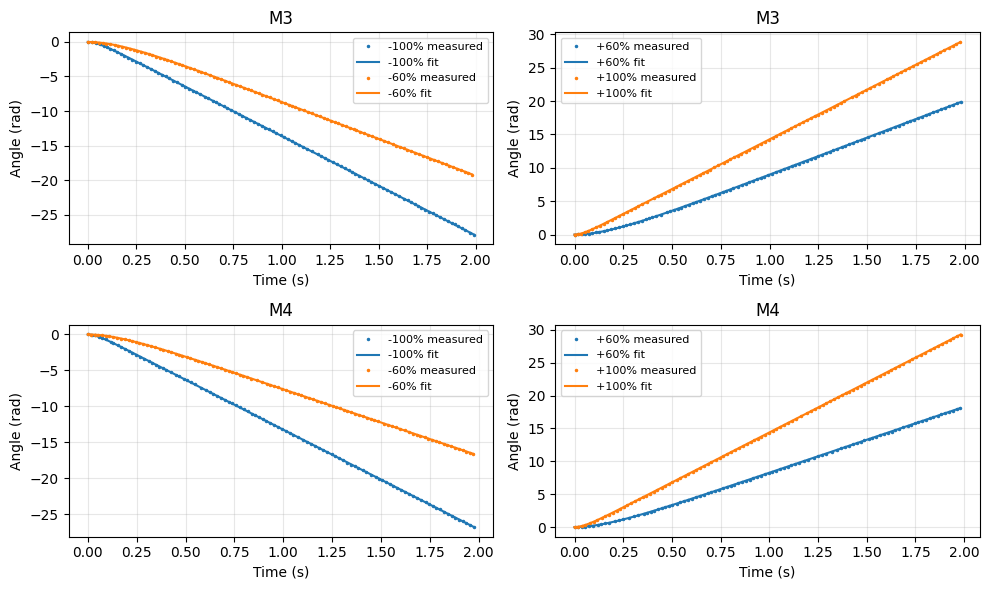

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for row, m in enumerate(motors):
    for col, levels in enumerate([[-100, -60], [60, 100]]):
        ax = axes[row, col]
        for pwm in levels:
            t, theta, fitted = curves[m, pwm]
            line, = ax.plot(t, theta, '.', ms=3, label=f'{pwm:+d}% measured')
            ax.plot(t, fitted, color=line.get_color(), label=f'{pwm:+d}% fit')
        ax.set(title=m, xlabel='Time (s)', ylabel='Angle (rad)')
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 2. Dead zone

Both motors move at −1 and +1 PWM. The threshold is unresolved, so no dead zone is added. For M4, I use the first complete run before its timestamp restart.


In [ ]:
low_rows = []
for m, filename in [('M3', 'deadzone_M3.txt'), ('M4', 'deadzone_M4_combined_runs.txt')]:
    a = np.loadtxt(folder + filename, delimiter=',')
    # Keep the first run before any clock restart.
    restarts = np.where(np.diff(a[:, 1]) <= 0)[0] + 1
    if len(restarts):
        a = a[:restarts[0]]
    for pwm in [-1, 1]:
        part = a[a[:, 2] == pwm]
        low_rows.append([m, pwm, part[-1, 0] - part[0, 0]])
display(pd.DataFrame(low_rows, columns=['Motor', 'PWM (%)', 'Angle change (deg)']))


,Motor,PWM (%),Angle change (deg)
0,M3,-1,-107.0
1,M3,1,93.0
2,M4,-1,-114.0
3,M4,1,103.0


## 3. Speed, time constant and parameters

I fit the ideal line $\omega_{ss}=s\,PWM$ over $20\leq |PWM|\leq80$ for each direction, and average $T_m$ over that range. Since $U=PWM\,U_{battery}/100$ and $\omega_{ss}=U/k_e$, $k_e=U_{battery}/(100s)$.

Lines show the speed fits; error bars show standard errors. The grey band is the untested interval between −1 and +1 PWM, not a measured dead zone.


M3


,Direction,Dead zone (% PWM),Slope (rad/s per %),k_e (V s/rad),Mean T_m (s),Battery (V)
0,Forward,unresolved (<1),0.1900,0.6475,0.2211,12.3
1,Backward,unresolved (<1),0.1826,0.6736,0.2215,12.3


M4


,Direction,Dead zone (% PWM),Slope (rad/s per %),k_e (V s/rad),Mean T_m (s),Battery (V)
0,Forward,unresolved (<1),0.1730,0.7108,0.1687,12.3
1,Backward,unresolved (<1),0.1578,0.7795,0.1823,12.3


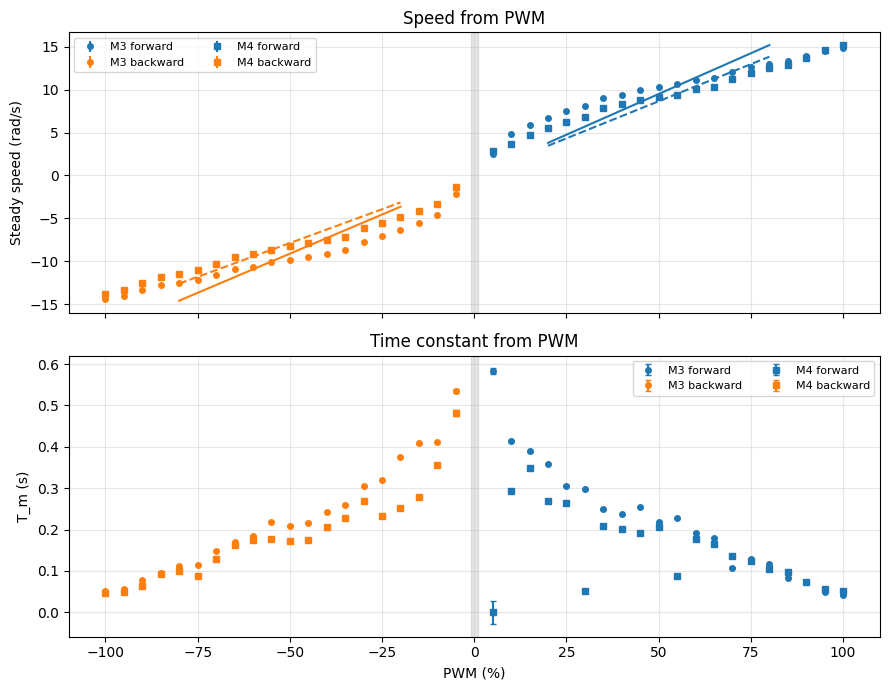

In [ ]:
params = {}
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for m, marker in [('M3', 'o'), ('M4', 's')]:
    table = []
    for sign, direction, color in [(1, 'Forward', 'tab:blue'), (-1, 'Backward', 'tab:orange')]:
        r = results[m]
        r = r[np.sign(r.index) == sign]
        # Estimate parameters from the middle PWM range.
        linear = r[(abs(r.index) >= 20) & (abs(r.index) <= 80)]
        x, y = linear.index.to_numpy(), linear.speed.to_numpy()
        # Least-squares speed line through zero.
        slope = np.dot(x, y) / np.dot(x, x)
        k_e = U_battery / (100 * slope)
        T_m = linear.T_m.mean()
        params[m, sign] = (k_e, T_m, slope)
        table.append([direction, 'unresolved (<1)', slope, k_e, T_m, U_battery])
        label = m + ' ' + direction.lower()
        axes[0].errorbar(r.index, r.speed, yerr=r.speed_SE, fmt=marker,
                        ms=4, color=color, label=label)
        axes[0].plot(x, slope * x, color=color, ls='-' if m == 'M3' else '--')
        axes[1].errorbar(r.index, r.T_m, yerr=r.T_m_SE, fmt=marker,
                        ms=4, capsize=2, color=color, label=label)
    print(m)
    display(pd.DataFrame(table, columns=['Direction', 'Dead zone (% PWM)',
        'Slope (rad/s per %)', 'k_e (V s/rad)', 'Mean T_m (s)', 'Battery (V)']).round(4))

for ax in axes:
    ax.axvspan(-1, 1, color='grey', alpha=0.2)
    ax.legend(fontsize=8, ncol=2)
axes[0].set(ylabel='Steady speed (rad/s)', title='Speed from PWM')
axes[1].set(xlabel='PWM (%)', ylabel='T_m (s)', title='Time constant from PWM')
plt.tight_layout()
plt.show()


## 4. Square wave: measured and simulated

The square input is ±60 PWM, with a 1 s period, for 8 s, followed by 1 s off. I use the step-test parameters and estimate motor voltage from the recorded PWM using U = (PWM / 100) × 12.3 V. This estimated voltage is interpolated for the simulation.

`np.gradient` gives speed. Both speeds use a centred 5-sample moving average (about 0.19 s). Angle is not smoothed.
$$RMSE=\sqrt{\operatorname{mean}((y-\hat y)^2)},\qquad fit=100\left(1-\frac{\|y-\hat y\|}{\|y-\bar y\|}\right).$$


In [ ]:
def smooth(speed):
    return pd.Series(speed).rolling(5, center=True, min_periods=1).mean().to_numpy()

def fit_percent(y, predicted):
    return 100 * (1 - np.linalg.norm(y - predicted) / np.linalg.norm(y - y.mean()))

signals, scores = {}, []
for m in motors:
    angle, time, pwm = np.loadtxt(folder + f'square_{m}.txt', delimiter=',', unpack=True)
    t_log = (time - time[0]) / 1000
    angle = (angle - angle[0]) * np.pi / 180
    U_log = pwm / 100 * U_battery

    def motor(state, t):
        speed, angle = state
        u = np.interp(t, t_log, U_log)       # recorded input, converted to volts
        k_e, T_m, slope = params[m, 1 if u >= 0 else -1]
        # During coasting, use the mean of both time constants.
        if u == 0:
            T_m = (params[m, 1][1] + params[m, -1][1]) / 2
        return np.array([-speed / T_m + u / (T_m * k_e), speed])

    y = odeint(motor, [0, 0], t_log, rtol=1e-6, atol=1e-8, mxstep=5000)
    # Differentiate using actual timestamps, then smooth the speed.
    speed = smooth(np.gradient(angle, t_log))
    model_speed = smooth(y[:, 0])
    signals[m] = (t_log, angle, pwm, speed, y[:, 1], model_speed)
    for name, measured, predicted in [('angle (rad)', angle, y[:, 1]),
                                       ('speed (rad/s)', speed, model_speed)]:
        rmse = np.sqrt(np.mean((measured - predicted)**2))
        scores.append([m, name, rmse, fit_percent(measured, predicted)])
display(pd.DataFrame(scores, columns=['Motor', 'Quantity', 'RMSE', 'Fit (%)']).round(3))


,Motor,Quantity,RMSE,Fit (%)
0,M3,angle (rad),0.646,58.312
1,M3,speed (rad/s),1.441,76.812
2,M4,angle (rad),2.376,-57.422
3,M4,speed (rad/s),1.224,79.275


Measured and simulated angle and speed, with PWM in green. Error is measured angle minus simulated angle.


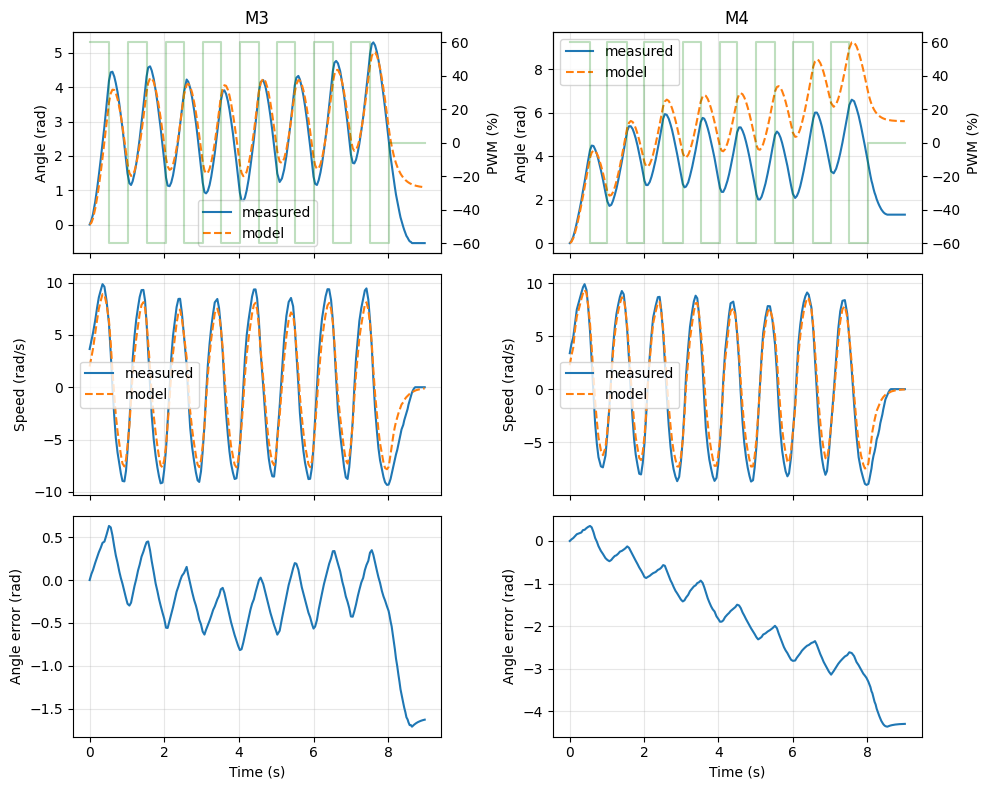

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(10, 8), sharex='col')
for col, m in enumerate(motors):
    t, angle, pwm, speed, predicted, model_speed = signals[m]
    axes[0, col].plot(t, angle, label='measured')
    axes[0, col].plot(t, predicted, '--', label='model')
    right = axes[0, col].twinx()
    right.step(t, pwm, where='post', color='green', alpha=0.25)
    right.set_ylabel('PWM (%)')
    right.grid(False)
    axes[0, col].set(title=m, ylabel='Angle (rad)')
    axes[1, col].plot(t, speed, label='measured')
    axes[1, col].plot(t, model_speed, '--', label='model')
    axes[1, col].set_ylabel('Speed (rad/s)')
    axes[2, col].plot(t, angle - predicted)
    axes[2, col].set(xlabel='Time (s)', ylabel='Angle error (rad)')
    axes[0, col].legend()
    axes[1, col].legend()
plt.tight_layout()
plt.show()


## 5. Artifacts

Zero drift, sampling intervals, coasting and speed noise are shown below. Coasting starts at the last powered sample, so switch-off timing is only known to one sample.


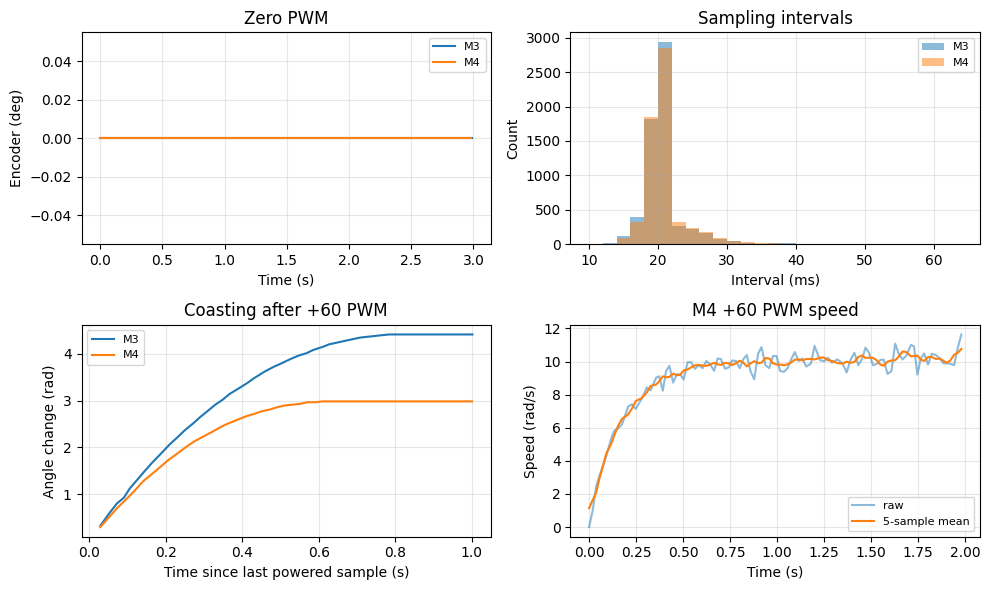

Motor,M3,M4
Zero drift (deg),0.000,0.000
Mean dt (ms),20.166,20.352
Min dt (ms),13.000,13.000
Max dt (ms),62.000,47.000
Coast (rad),4.416,2.985
speed x T_m (rad),2.139,1.780
Raw speed std (rad/s),0.801,0.467
Smoothed std (rad/s),0.367,0.192


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
checks = []
for m in motors:
    a = steps[m]
    zero = parts[m][0]  # Initial motor-off record
    dt = np.diff(a[:, 1])
    axes[0, 0].plot((zero[:, 1] - zero[0, 1]) / 1000, zero[:, 0], label=m)
    axes[0, 1].hist(dt, bins=np.arange(10, 66, 2), alpha=0.5, label=m)
    i = next(i for i, p in enumerate(parts[m]) if p[0, 2] == 60)
    last, coast = parts[m][i][-1], parts[m][i + 1]
    coast_angle = (coast[:, 0] - last[0]) * np.pi / 180
    axes[1, 0].plot((coast[:, 1] - last[1]) / 1000, coast_angle, label=m)
    t, theta, fitted = curves[m, 60]
    raw = np.gradient(theta, t)
    # Compare noise after the main acceleration.
    noise = [np.std(v[(t > 1) & (t < 1.9)]) for v in [raw, smooth(raw)]]
    checks.append([m, np.ptp(zero[:, 0]), dt.mean(), dt.min(), dt.max(),
                   coast_angle[-1], results[m].loc[60, 'speed'] * results[m].loc[60, 'T_m'], *noise])
    if m == 'M4':
        axes[1, 1].plot(t, raw, alpha=0.5, label='raw')
        axes[1, 1].plot(t, smooth(raw), label='5-sample mean')

for ax, title, xlabel, ylabel in zip(axes.flat,
    ['Zero PWM', 'Sampling intervals', 'Coasting after +60 PWM', 'M4 +60 PWM speed'],
    ['Time (s)', 'Interval (ms)', 'Time since last powered sample (s)', 'Time (s)'],
    ['Encoder (deg)', 'Count', 'Angle change (rad)', 'Speed (rad/s)']):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(checks, columns=['Motor', 'Zero drift (deg)', 'Mean dt (ms)',
    'Min dt (ms)', 'Max dt (ms)', 'Coast (rad)', 'speed x T_m (rad)',
    'Raw speed std (rad/s)', 'Smoothed std (rad/s)']).set_index('Motor').T.round(3))


Reversal delay ends at the first sample moving in the new direction. It includes inertia and sampling delay. The high-PWM speed increase checks for saturation.


In [ ]:
for m in motors:
    t, angle, pwm, speed, predicted, model_speed = signals[m]
    velocity = np.gradient(angle, t)
    # Find changes from positive to negative PWM, or back.
    switches = np.where(pwm[1:] * pwm[:-1] < 0)[0] + 1
    delays = []
    for i in switches:
        moving = np.where((t >= t[i]) & (t < t[i] + 0.5) & (velocity * pwm[i] > 0))[0]
        if len(moving):
            delays.append(t[moving[0]] - t[i])
    r = results[m]
    gains = [abs(r.loc[s*100, 'speed']) - abs(r.loc[s*80, 'speed']) for s in [1, -1]]
    print(f'{m}: reversal delay {min(delays):.3f}–{max(delays):.3f} s; '
          f'speed increase 80→100 PWM: {gains[0]:.2f} forward, {gains[1]:.2f} backward rad/s')


M3: reversal delay 0.088–0.125 s; speed increase 80→100 PWM: 1.85 forward, 1.82 backward rad/s
M4: reversal delay 0.069–0.129 s; speed increase 80→100 PWM: 2.66 forward, 2.39 backward rad/s


Reading and saving data makes the interval longer than the 5 ms timer. Integer-degree readings make speed noisy. Coasting exceeds the estimate $\omega_{ss}T_m$, and speed has no clear high-PWM plateau. Two display checks cannot show voltage sag during a run.


## 6. Repeatability

I compare the two older step recordings in `motor_data/repeatability/`. Each file records both motors at the same PWM levels, in steps of 10. The six columns are `phase, PWM, M4 angle (deg), M3 angle (deg), time (ms), battery (V)`.

Only phase 1 contains powered motion; phase 0 is motor off even when its PWM column is nonzero. I fit each nonzero level with the same angle model. These files have their own voltage readings, so I use those instead of 12.3 V.

The table gives mean percentage changes relative to run 1 across matching levels. The plot compares speed per volt to account for the battery difference.


,Run,Min battery (V),Max battery (V)
0,1,11.636,11.675
1,2,11.286,11.325


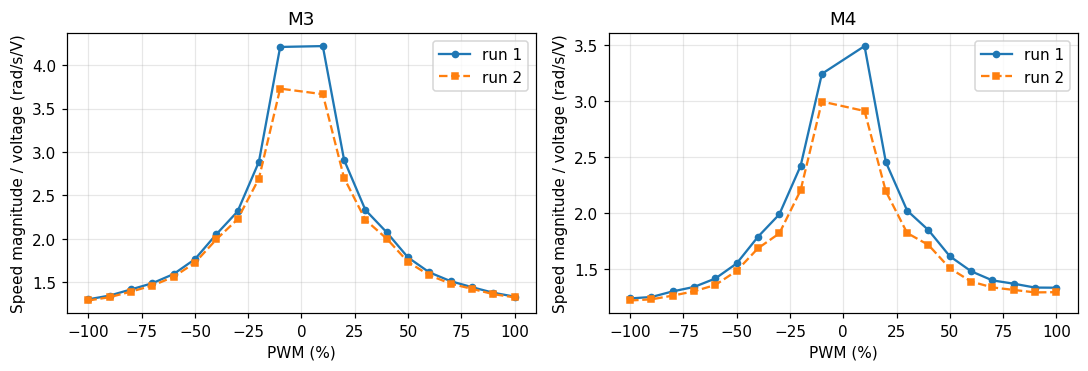

,Motor,Speed change (%),Speed per volt change (%),Run 1 mean T_m (s),Run 2 mean T_m (s)
0,M3,-6.489,-3.687,0.149,0.136
1,M4,-8.756,-6.022,0.160,0.144


In [ ]:
repeat_rows, battery_rows = [], []
for run in [1, 2]:
    a = np.loadtxt(folder + f'repeatability/steps_both_motors_run_{run}_with_voltage.txt')
    battery_rows.append([run, a[:, 5].min(), a[:, 5].max()])
    for pwm in np.unique(a[:, 1]):
        if pwm == 0:
            continue
        # Fit the powered samples only; the timer resets at each PWM level.
        part = a[(a[:, 0] == 1) & (a[:, 1] == pwm)]
        t = (part[:, 4] - part[0, 4]) / 1000
        volts = abs(pwm) / 100 * part[:, 5].mean()
        for m, col in [('M3', 3), ('M4', 2)]:
            theta = np.deg2rad(part[:, col] - part[0, col])
            popt, err = fit_step(t, theta)
            repeat_rows.append([run, m, pwm, abs(popt[0]), abs(popt[0]) / volts, popt[1]])

repeat = pd.DataFrame(repeat_rows, columns=['run', 'motor', 'PWM', 'speed', 'speed_per_volt', 'T_m'])
display(pd.DataFrame(battery_rows, columns=['Run', 'Min battery (V)', 'Max battery (V)']).round(3))

comparison = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, m in zip(axes, motors):
    run1 = repeat[(repeat.motor == m) & (repeat.run == 1)].set_index('PWM')
    run2 = repeat[(repeat.motor == m) & (repeat.run == 2)].set_index('PWM')
    # Compare magnitudes at the same PWM, relative to run 1.
    speed_change = 100 * (run2.speed / run1.speed - 1)
    gain_change = 100 * (run2.speed_per_volt / run1.speed_per_volt - 1)
    comparison.append([m, speed_change.mean(), gain_change.mean(), run1.T_m.mean(), run2.T_m.mean()])
    ax.plot(run1.index, run1.speed_per_volt, 'o-', ms=4, label='run 1')
    ax.plot(run2.index, run2.speed_per_volt, 's--', ms=4, label='run 2')
    ax.set(title=m, xlabel='PWM (%)', ylabel='Speed magnitude / voltage (rad/s/V)')
    ax.legend()
plt.tight_layout()
plt.show()

repeat_summary = pd.DataFrame(comparison, columns=['Motor', 'Speed change (%)',
    'Speed per volt change (%)', 'Run 1 mean T_m (s)', 'Run 2 mean T_m (s)'])
display(repeat_summary.round(3))


Run 2 has lower fitted speed: the mean decrease is 6.5% for M3 and 8.8% for M4. After dividing speed by voltage, the decreases are 3.7% and 6.0%. The runs follow similar trends, but some difference remains after this voltage adjustment. The mean time constants also differ between runs, as shown in the table.


## 7. Conclusions

**Model.** Square-wave speed fits are 76.8% for M3 and 79.3% for M4; angle fits are 58.3% and −57.4%. The M4 angle prediction is worse than using a constant mean angle. Its largest error is 4.37 rad at 8.55 s. Speed errors add up in angle, and T_m changes with PWM, so constant parameters are only an approximation.

**Directions.** Forward speed slopes are 4.0% higher for M3 and 9.2% higher for M4, relative to the mean of both directions. Mean T_m differs by 0.2% and 7.7%. I would use separate motor and direction parameters because equal PWM does not give equal speeds.

**Artifacts.** No drift is visible in the first 3 s. Mean sampling intervals are 20.17 ms and 20.35 ms. Coasting, speed noise and unequal motor responses matter for odometry; both encoders and actual timestamps are needed. Both motors move at ±1 PWM.

**Signal.** The square wave reverses a moving wheel. It shows reversal delay and accumulated angle error that separate steps miss. Each half-period is 0.5 s, only a few time constants, so speed does not fully settle. Backlash cannot be separated from inertia here. Chirp files are kept as extra data, without analysis.
